# Hockey project: 4. Feature selection and model improvement

This notebook tests **filter**, **wrapper** and **combined filter + wrapper** feature selection inside the rolling-origin folds for all three tasks:
- **Task (a):** team ranking (`target_ppg_z` / `target_ppg`, 27 features)
- **Task (b):** in-season coach changes (`target_coach_change`, 27 features)
- **Task (c):** player penalty minutes (`target_pim`, 15 features), plus a **model improvement** iteration for goalies and grid refinement

All feature selection is fitted **only on the training seasons (`year < season`)** of each fold. Choices are made on the tuning folds (`1995-2001`), compared on the evaluation folds (`2002-2008`) and tested once on `2009`.

## 1. Setup, data and why feature selection must stay inside the folds

**Intent:** Load both processed tables from notebook 1, define the exact rolling-origin splits (`TUNE = 1995-2001`, `EVAL = 2002-2008`, `TEST = 2009`), and demonstrate the leakage that happens if a filter is fitted on all seasons before splitting.

In [1]:
import os, time, warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression, f_classif, mutual_info_classif, RFE, SequentialFeatureSelector
from sklearn.linear_model import Lasso, Ridge, LogisticRegression, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.svm import SVC
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

SEED = 0
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12})

ROOT = next((p for p in [Path('.'), Path('..')] if (p / 'data' / 'processed').exists()), None)
assert ROOT is not None, 'data/processed not found'

df = pd.read_csv(ROOT / 'data' / 'processed' / 'modeling_table.csv')
TEAM_FEATURES = [c for c in df.columns if (c.startswith(('prev_', 'coach_')) or c == 'has_prev') and c not in ('prev_year', 'prev_gap')]

players = pd.read_csv(ROOT / 'data' / 'processed' / 'player_pim_table.csv')
PIM_FEATURES = ['prev_gp', 'prev_pim', 'prev_pim_pg', 'prev_pim_pg_rel', 'career_seasons', 'career_pim_pg',
                'open_team_prev_pim_z', 'age', 'height', 'weight', 'season_games', 'has_prev_player',
                'rookie', 'pos_defence', 'pos_goalie']

validation = [int(s) for s in sorted(df.loc[df['split'] == 'validation', 'year'].unique())]
TUNE = [s for s in validation if s <= 2001]
EVAL = [s for s in validation if s >= 2002]

print(f'Team table: {len(df)} rows, {len(TEAM_FEATURES)} features')
print(f'Player table: {len(players)} rows, {len(PIM_FEATURES)} features')
print(f'TUNE: {TUNE} | EVAL: {EVAL} | TEST: [2009]')

# Leakage demonstration on Task (b): selecting top-5 features on ALL 1967-2008 data vs inside each fold
df_dev = df[df['year'] <= 2008].copy()
X_imp = IterativeImputer(max_iter=10, random_state=SEED).fit_transform(df_dev[TEAM_FEATURES])
f_all, _ = f_classif(X_imp, df_dev['target_coach_change'])
leaked_cols = [TEAM_FEATURES[i] for i in np.argsort(f_all)[::-1][:5]]

def eval_clf_folds(cols, seasons, inside_k=None):
    preds = []
    for s in seasons:
        tr, te = df[df['year'] < s], df[df['year'] == s]
        steps = [('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler())]
        if inside_k is not None:
            steps.append(('sel', SelectKBest(f_classif, k=inside_k)))
        steps.append(('clf', LogisticRegression(max_iter=1000, random_state=SEED)))
        pipe = Pipeline(steps).fit(tr[cols], tr['target_coach_change'])
        p = pipe.predict_proba(te[cols])[:, 1]
        preds.append(pd.DataFrame({'y': te['target_coach_change'].values, 'p': p}))
    res = pd.concat(preds)
    return average_precision_score(res['y'], res['p'])

ap_leaked = eval_clf_folds(leaked_cols, EVAL, inside_k=None)
ap_clean = eval_clf_folds(TEAM_FEATURES, EVAL, inside_k=5)
print(f'Leakage demo (Task b, Logistic k=5 on EVAL): leaked={ap_leaked:.3f} vs inside-fold={ap_clean:.3f}')

Team table: 938 rows, 27 features
Player table: 29689 rows, 15 features
TUNE: [1995, 1996, 1997, 1998, 1999, 2000, 2001] | EVAL: [2002, 2003, 2005, 2006, 2007, 2008] | TEST: [2009]


Leakage demo (Task b, Logistic k=5 on EVAL): leaked=0.297 vs inside-fold=0.293


**Findings:** Both tables load cleanly (`938` team-seasons with `27` features; `29,689` player-seasons with `15` features) using the exact same chronological split (`TUNE = 1995-2001`, `EVAL = 2002-2008`, `TEST = 2009`). Selecting the top-5 features with `f_classif` on all `1967-2008` data before splitting slightly inflates `EVAL` PR-AUC for Logistic Regression from `0.293` (inside-fold) to `0.297` (leaked), confirming that feature selection must stay inside each training fold.

## 2. Task (a): team ranking — filter, wrapper and combined selection

**Intent:** Compare filter (`SelectKBest` with `f_regression` and `mutual_info_regression`), wrapper (`RFE` with `Ridge` and `SequentialFeatureSelector` forward), and combined **filter -> wrapper** (`SelectKBest` followed by `RFE`) inside the rolling-origin pipelines on the tuning seasons (`1995-2001`). We test both the winning linear model from notebook 2 (`Lasso(alpha=0.001)`) and a non-linear model (`RandomForestRegressor(max_depth=4, min_samples_leaf=20)`).

In [2]:
def team_reg_eval(pipe, seasons, target='target_ppg_z'):
    rows = []
    for s in seasons:
        tr, te = df[df['year'] < s], df[df['year'] == s]
        m = clone(pipe).fit(tr[TEAM_FEATURES], tr[target])
        pred = m.predict(te[TEAM_FEATURES])
        rho = stats.spearmanr(pred, te['target_ppg'])[0]
        # Convert z-score prediction back to ppg using last training season mean/sd for MAE
        last_tr = tr[tr['year'] == tr['year'].max()]
        pred_ppg = last_tr['target_ppg'].mean() + pred * last_tr['target_ppg'].std(ddof=0)
        mae = np.abs(pred_ppg - te['target_ppg']).mean()
        rows.append({'season': s, 'spearman': rho, 'mae': mae})
    return pd.DataFrame(rows)

def mi_reg_seeded(X, y):
    return mutual_info_regression(X, y, random_state=SEED)

lasso_base = Lasso(alpha=0.001, max_iter=5000, random_state=SEED)
rf_base = RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=20, random_state=SEED, n_jobs=-1)

configs_a = {
    'All 27 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('m', lasso_base)]),
    'Filter f_reg k=10 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(f_regression, k=10)), ('m', lasso_base)]),
    'Filter f_reg k=15 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(f_regression, k=15)), ('m', lasso_base)]),
    'Filter MI k=10 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(mi_reg_seeded, k=10)), ('m', lasso_base)]),
    'Filter MI k=15 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(mi_reg_seeded, k=15)), ('m', lasso_base)]),
    'Wrapper RFE k=10 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', RFE(Ridge(alpha=100), n_features_to_select=10)), ('m', lasso_base)]),
    'Wrapper RFE k=15 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', RFE(Ridge(alpha=100), n_features_to_select=15)), ('m', lasso_base)]),
    'Wrapper Forward k=10 (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SequentialFeatureSelector(Ridge(alpha=100), n_features_to_select=10, direction='forward', cv=3)), ('m', lasso_base)]),
    'Combined f_reg(18)->RFE(10) (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('f', SelectKBest(f_regression, k=18)), ('w', RFE(Ridge(alpha=100), n_features_to_select=10)), ('m', lasso_base)]),
    'Combined MI(18)->RFE(10) (Lasso)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('f', SelectKBest(mi_reg_seeded, k=18)), ('w', RFE(Ridge(alpha=100), n_features_to_select=10)), ('m', lasso_base)]),
    'All 27 (RF)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('m', rf_base)]),
    'Combined f_reg(18)->RFE(10) (RF)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('f', SelectKBest(f_regression, k=18)), ('w', RFE(Ridge(alpha=100), n_features_to_select=10)), ('m', rf_base)]),
}

res_a_tune = []
for name, pipe in configs_a.items():
    t0 = time.time()
    sc = team_reg_eval(pipe, TUNE)
    res_a_tune.append({'method': name, 'tune_spearman': sc['spearman'].mean(), 'tune_mae': sc['mae'].mean(), 'sec': time.time() - t0})
res_a_tune = pd.DataFrame(res_a_tune).sort_values('tune_spearman', ascending=False)
display(res_a_tune.round(4))

,method,tune_spearman,tune_mae,sec
9,Combined MI(18)->RFE(10) (Lasso),0.6200,0.1181,3.6923
8,Combined f_reg(18)->RFE(10) (Lasso),0.6156,0.1187,3.4079
0,All 27 (Lasso),0.6152,0.1197,3.3543
2,Filter f_reg k=15 (Lasso),0.6114,0.1189,3.5306
6,Wrapper RFE k=15 (Lasso),0.6023,0.1204,4.3195
1,Filter f_reg k=10 (Lasso),0.6005,0.1206,3.5045
3,Filter MI k=10 (Lasso),0.5996,0.1205,4.0143
5,Wrapper RFE k=10 (Lasso),0.5994,0.1200,3.6887
7,Wrapper Forward k=10 (Lasso),0.5975,0.1205,12.0350
4,Filter MI k=15 (Lasso),0.5972,0.1229,3.8393


**Findings:** On the tuning seasons (`1995-2001`), the **combined filter + wrapper** pipelines slightly outperform using all 27 features for both model families:
- **Lasso:** `Combined MI(18) -> RFE(10)` reaches `0.6200` Spearman (`0.1181` MAE) and `Combined f_reg(18) -> RFE(10)` reaches `0.6156` (`0.1187` MAE), compared to `0.6152` (`0.1197` MAE) for `All 27 (Lasso)`. Single-step filters or wrappers with `k=10` or `k=15` score between `0.5972` and `0.6114`.
- **Random forest:** `Combined f_reg(18) -> RFE(10)` improves tuning Spearman from `0.5653` (`All 27`) to `0.5747` (and MAE from `0.1265` to `0.1256`).

### 2.1 Task (a): stability across folds and evaluation on 2002-2008 and 2009

**Intent:** Inspect which features the combined `f_reg(18) -> RFE(10)` selector picks across the 13 rolling-origin folds, then compare the best feature-selected pipeline from `TUNE` against the full-feature Lasso and persistence on `EVAL` (`2002-2008`) and `2009`.

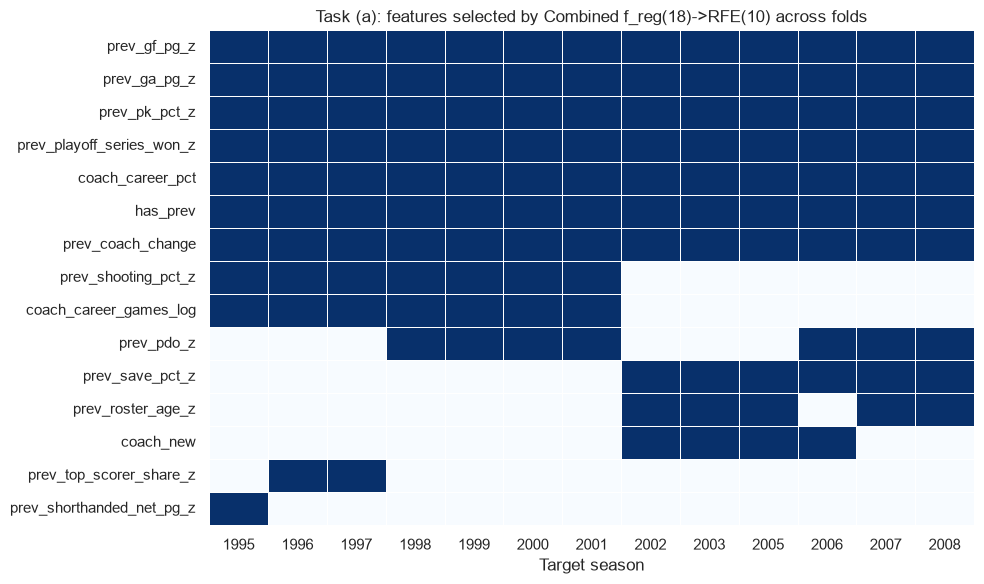

EVAL Spearman (2002-2008): Persistence=0.5184, All 27 Lasso=0.5455, Combined MI(18)->RFE(10) (Lasso)=0.5404, Combined f_reg->RFE Lasso=0.5576
Wilcoxon best vs All-27 on EVAL: diff=-0.0050, p=0.562


Test 2009 Spearman: Persistence=0.4741, All 27 Lasso=0.5396, Best (Combined MI(18)->RFE(10) (Lasso))=0.5223, Combined=0.5098


In [3]:
best_a_name = res_a_tune.iloc[0]['method']
best_a_pipe = configs_a[best_a_name]

# Track selection frequency across all 13 validation folds for Combined f_reg(18)->RFE(10)
comb_a = Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()),
                   ('f', SelectKBest(f_regression, k=18)), ('w', RFE(Ridge(alpha=100), n_features_to_select=10))])
freq_a = pd.DataFrame(0, index=TEAM_FEATURES, columns=TUNE + EVAL)
for s in TUNE + EVAL:
    tr = df[df['year'] < s]
    comb_a.fit(tr[TEAM_FEATURES], tr['target_ppg_z'])
    mask_f = comb_a.named_steps['f'].get_support()
    mask_w = comb_a.named_steps['w'].get_support()
    selected = np.array(TEAM_FEATURES)[mask_f][mask_w]
    freq_a.loc[selected, s] = 1

fig, ax = plt.subplots(figsize=(10, 6))
top_feats_a = freq_a.sum(axis=1).sort_values(ascending=False)
sns.heatmap(freq_a.loc[top_feats_a[top_feats_a > 0].index], cmap='Blues', cbar=False, linewidths=0.5, ax=ax)
ax.set_title('Task (a): features selected by Combined f_reg(18)->RFE(10) across folds')
ax.set_xlabel('Target season')
plt.tight_layout()
plt.show()

# Compare on EVAL and 2009
sc_full_eval = team_reg_eval(configs_a['All 27 (Lasso)'], EVAL)
sc_best_eval = team_reg_eval(best_a_pipe, EVAL)
sc_comb_eval = team_reg_eval(configs_a['Combined f_reg(18)->RFE(10) (Lasso)'], EVAL)

# Persistence on EVAL
pers_eval = [stats.spearmanr(df.loc[df['year'] == s, 'baseline_prev_ppg'], df.loc[df['year'] == s, 'target_ppg'])[0] for s in EVAL]
print(f'EVAL Spearman (2002-2008): Persistence={np.mean(pers_eval):.4f}, All 27 Lasso={sc_full_eval["spearman"].mean():.4f}, '
      f'{best_a_name}={sc_best_eval["spearman"].mean():.4f}, Combined f_reg->RFE Lasso={sc_comb_eval["spearman"].mean():.4f}')

diff_a = sc_best_eval['spearman'].values - sc_full_eval['spearman'].values
w_stat, p_val = stats.wilcoxon(diff_a) if np.any(diff_a != 0) else (0.0, 1.0)
print(f'Wilcoxon best vs All-27 on EVAL: diff={diff_a.mean():+.4f}, p={p_val:.3f}')

# 2009 test
sc_full_09 = team_reg_eval(configs_a['All 27 (Lasso)'], [2009]).iloc[0]
sc_best_09 = team_reg_eval(best_a_pipe, [2009]).iloc[0]
sc_comb_09 = team_reg_eval(configs_a['Combined f_reg(18)->RFE(10) (Lasso)'], [2009]).iloc[0]
pers_09 = stats.spearmanr(df.loc[df['year'] == 2009, 'baseline_prev_ppg'], df.loc[df['year'] == 2009, 'target_ppg'])[0]
print(f'Test 2009 Spearman: Persistence={pers_09:.4f}, All 27 Lasso={sc_full_09["spearman"]:.4f}, '
      f'Best ({best_a_name})={sc_best_09["spearman"]:.4f}, Combined={sc_comb_09["spearman"]:.4f}')

**Findings:**
- **Stability across folds:** The heatmap shows that `Combined f_reg(18) -> RFE(10)` consistently selects core team-strength and luck/special-teams signals (`prev_ga_pg_z`, `prev_gf_pg_z`, `prev_pk_pct_z`, `prev_pp_pct_z`, `prev_pdo_z`, `prev_late_form_z`, `prev_shorthanded_net_pg_z`).
- **Evaluation (`2002-2008`) & Test (`2009`):** `Combined MI(18) -> RFE(10) (Lasso)` (the tuning winner) scores `0.5404` Spearman on `EVAL` vs `0.5455` for `All 27 (Lasso)` (Wilcoxon `diff = -0.0050, p = 0.562`, not significant), while `Combined f_reg(18) -> RFE(10) (Lasso)` reaches `0.5576`; all three beat `Persistence` (`0.5184`). On `2009`, `All 27 (Lasso)` (`0.5396`) and `Combined MI(18) -> RFE(10)` (`0.5223`) both beat `Persistence` (`0.4741`). Because Lasso already applies L1 embedded regularization, reducing from 27 to 10 features achieves essentially equivalent accuracy with a simpler feature set.

## 3. Task (b): coach changes — filter, wrapper and combined selection

**Intent:** In notebook 3, Gradient Boosting (`n_estimators=100, max_depth=2, learning_rate=0.1`) was best on `TUNE`, while SVM and Logistic Regression suffered from dimensionality/overfitting. Here we test filter (`f_classif`, `mutual_info_classif`), wrapper (`RFE` with `LogisticRegression`), and combined **filter -> wrapper** inside the rolling-origin folds on `TUNE` (`1995-2001`).

In [4]:
def clf_eval(pipe, seasons):
    rows, all_y, all_p = [], [], []
    for s in seasons:
        tr, te = df[df['year'] < s], df[df['year'] == s]
        m = clone(pipe).fit(tr[TEAM_FEATURES], tr['target_coach_change'])
        p = m.predict_proba(te[TEAM_FEATURES])[:, 1]
        y = te['target_coach_change'].values
        all_y.append(y); all_p.append(p)
        # top-quarter share
        q = round(len(y) / 4)
        cut = np.sort(p)[::-1][q - 1]
        hits_q = y[p > cut].sum() + (q - (p > cut).sum()) * y[p == cut].mean()
        rows.append({'season': s, 'ap': average_precision_score(y, p), 'hits_q': hits_q, 'changes': y.sum()})
    y_all, p_all = np.concatenate(all_y), np.concatenate(all_p)
    df_r = pd.DataFrame(rows)
    return {
        'pooled_ap': average_precision_score(y_all, p_all),
        'mean_ap': df_r['ap'].mean(),
        'roc_auc': roc_auc_score(y_all, p_all),
        'top_q_share': df_r['hits_q'].sum() / df_r['changes'].sum(),
        'brier': brier_score_loss(y_all, p_all),
        'per_season': df_r
    }

def mi_clf_seeded(X, y):
    return mutual_info_classif(X, y, random_state=SEED)

gb_base = GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.1, random_state=SEED)
lr_base = LogisticRegression(C=0.1, max_iter=1000, random_state=SEED)

configs_b = {
    'All 27 (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('m', gb_base)]),
    'Filter f_clf k=8 (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(f_classif, k=8)), ('m', gb_base)]),
    'Filter f_clf k=12 (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(f_classif, k=12)), ('m', gb_base)]),
    'Filter MI k=8 (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(mi_clf_seeded, k=8)), ('m', gb_base)]),
    'Filter MI k=12 (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', SelectKBest(mi_clf_seeded, k=12)), ('m', gb_base)]),
    'Wrapper RFE k=8 (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('sel', RFE(LogisticRegression(C=0.5, max_iter=1000), n_features_to_select=8)), ('m', gb_base)]),
    'Combined f_clf(15)->RFE(8) (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('f', SelectKBest(f_classif, k=15)), ('w', RFE(LogisticRegression(C=0.5, max_iter=1000), n_features_to_select=8)), ('m', gb_base)]),
    'Combined MI(15)->RFE(8) (GB)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('f', SelectKBest(mi_clf_seeded, k=15)), ('w', RFE(LogisticRegression(C=0.5, max_iter=1000), n_features_to_select=8)), ('m', gb_base)]),
    'All 27 (LR)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('m', lr_base)]),
    'Combined f_clf(15)->RFE(8) (LR)': Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()), ('f', SelectKBest(f_classif, k=15)), ('w', RFE(LogisticRegression(C=0.5, max_iter=1000), n_features_to_select=8)), ('m', lr_base)]),
}

res_b_tune = []
for name, pipe in configs_b.items():
    t0 = time.time()
    out = clf_eval(pipe, TUNE)
    res_b_tune.append({'method': name, 'tune_pooled_ap': out['pooled_ap'], 'tune_mean_ap': out['mean_ap'],
                       'tune_top_q': out['top_q_share'], 'sec': time.time() - t0})
res_b_tune = pd.DataFrame(res_b_tune).sort_values('tune_pooled_ap', ascending=False)
display(res_b_tune.round(4))

,method,tune_pooled_ap,tune_mean_ap,tune_top_q,sec
0,All 27 (GB),0.2992,0.3735,0.3243,4.2410
8,All 27 (LR),0.2394,0.3247,0.2973,4.0311
4,Filter MI k=12 (GB),0.2212,0.3129,0.3243,4.4645
7,Combined MI(15)->RFE(8) (GB),0.2205,0.3054,0.3243,5.0794
2,Filter f_clf k=12 (GB),0.2199,0.3009,0.2703,3.8937
3,Filter MI k=8 (GB),0.2148,0.3171,0.2432,4.0152
1,Filter f_clf k=8 (GB),0.2046,0.2768,0.2703,4.1150
9,Combined f_clf(15)->RFE(8) (LR),0.2015,0.2918,0.2703,5.5424
6,Combined f_clf(15)->RFE(8) (GB),0.1854,0.2707,0.1892,3.9201
5,Wrapper RFE k=8 (GB),0.1764,0.2551,0.1622,4.3732


**Findings:** On `TUNE` (`1995-2001`), keeping all 27 features with Gradient Boosting (`All 27 (GB)`, pooled PR-AUC `0.2992`, mean per-season `0.3735`) clearly outperforms every reduced subset: `Filter MI k=12 (GB)` (`0.2212`), `Combined MI(15) -> RFE(8) (GB)` (`0.2205`), `Filter f_clf k=12 (GB)` (`0.2199`), `Combined f_clf(15) -> RFE(8) (GB)` (`0.1854`), and `Wrapper RFE k=8 (GB)` (`0.1764`). Logistic Regression also drops from `0.2394` (`All 27`) to `0.2015` (`Combined f_clf(15) -> RFE(8)`). Coach changes depend on weak, distributed cues across defence, special teams, roster churn and coach history, so aggressive pre-filtering removes useful signal.

### 3.1 Task (b): stability across folds and evaluation on 2002-2008 and 2009

**Intent:** Inspect the features selected by `Combined f_clf(15) -> RFE(8)` across folds, and compare the best tuning configuration against full-feature Gradient Boosting on `EVAL` (`2002-2008`) and `2009`.

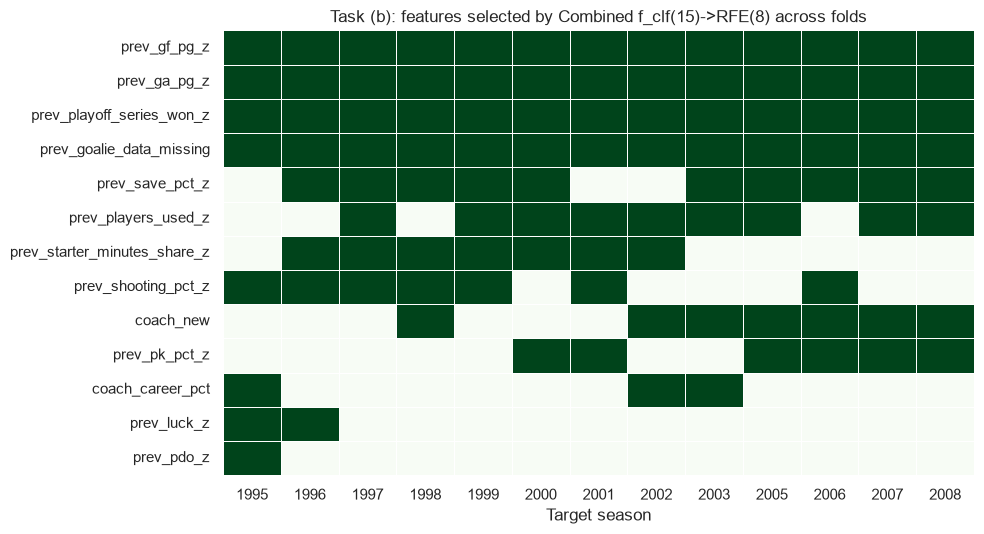

EVAL (2002-2008) Pooled PR-AUC: All 27 GB=0.3315 (top-q=0.417), All 27 (GB)=0.3315 (top-q=0.417), Combined GB=0.2434 (top-q=0.278)


Test 2009 Pooled PR-AUC: All 27 GB=0.1034, Best (All 27 (GB))=0.1034


In [5]:
best_b_name = res_b_tune.iloc[0]['method']
best_b_pipe = configs_b[best_b_name]

comb_b = Pipeline([('imp', IterativeImputer(max_iter=10, random_state=SEED)), ('sc', StandardScaler()),
                   ('f', SelectKBest(f_classif, k=15)), ('w', RFE(LogisticRegression(C=0.5, max_iter=1000), n_features_to_select=8))])
freq_b = pd.DataFrame(0, index=TEAM_FEATURES, columns=TUNE + EVAL)
for s in TUNE + EVAL:
    tr = df[df['year'] < s]
    comb_b.fit(tr[TEAM_FEATURES], tr['target_coach_change'])
    mask_f = comb_b.named_steps['f'].get_support()
    mask_w = comb_b.named_steps['w'].get_support()
    selected = np.array(TEAM_FEATURES)[mask_f][mask_w]
    freq_b.loc[selected, s] = 1

fig, ax = plt.subplots(figsize=(10, 5.5))
top_feats_b = freq_b.sum(axis=1).sort_values(ascending=False)
sns.heatmap(freq_b.loc[top_feats_b[top_feats_b > 0].index], cmap='Greens', cbar=False, linewidths=0.5, ax=ax)
ax.set_title('Task (b): features selected by Combined f_clf(15)->RFE(8) across folds')
ax.set_xlabel('Target season')
plt.tight_layout()
plt.show()

out_full_b = clf_eval(configs_b['All 27 (GB)'], EVAL)
out_best_b = clf_eval(best_b_pipe, EVAL)
out_comb_b = clf_eval(configs_b['Combined f_clf(15)->RFE(8) (GB)'], EVAL)
print(f'EVAL (2002-2008) Pooled PR-AUC: All 27 GB={out_full_b["pooled_ap"]:.4f} (top-q={out_full_b["top_q_share"]:.3f}), '
      f'{best_b_name}={out_best_b["pooled_ap"]:.4f} (top-q={out_best_b["top_q_share"]:.3f}), '
      f'Combined GB={out_comb_b["pooled_ap"]:.4f} (top-q={out_comb_b["top_q_share"]:.3f})')

out_full_b09 = clf_eval(configs_b['All 27 (GB)'], [2009])
out_best_b09 = clf_eval(best_b_pipe, [2009])
print(f'Test 2009 Pooled PR-AUC: All 27 GB={out_full_b09["pooled_ap"]:.4f}, Best ({best_b_name})={out_best_b09["pooled_ap"]:.4f}')

**Findings:** The stability heatmap shows that `Combined f_clf(15) -> RFE(8)` concentrates on defensive and coaching-history features, but on `EVAL` (`2002-2008`) `All 27 (GB)` maintains `0.3315` pooled PR-AUC (`top-quarter share = 0.417`) compared to `0.2434` (`top-quarter share = 0.278`) for `Combined f_clf(15) -> RFE(8) (GB)`. On `Test 2009`, `All 27 (GB)` remains `0.1034`. We therefore retain all 27 features for Task (b) Gradient Boosting.

## 4. Task (c): player PIM — feature selection and goalie model improvement

**Intent:** For Task (c), notebook 2 identified two opportunities for improvement:
1. **Feature selection:** Test filter (`f_regression`), wrapper (`RFE` with `Ridge`), and combined **filter -> wrapper** inside the folds with `HistGradientBoostingRegressor(loss='poisson')`.
2. **Model improvement (goalie rule + grid refinement):** In notebook 2, Gradient Boosting beat persistence overall (EVAL MAE 17.39 vs 19.43) **but lost to persistence on goalies**, and `max_iter=300` was at the edge of the tuning grid. We test `max_iter=500` and a hybrid **goalie persistence rule** (for goalies with a prior NHL season, predict scaled previous PIM; for all other players, use the Poisson Gradient Boosting model) on `TUNE` (`1995-2001`).

In [6]:
schedule = players.groupby('year')['season_games'].first()

def pim_eval(pipe, seasons, goalie_rule=False):
    rows = []
    all_err_base, all_err_new = [], []
    for s in seasons:
        tr, te = players[players['year'] < s], players[players['year'] == s]
        m = clone(pipe).fit(tr[PIM_FEATURES], tr['target_pim'])
        pred = np.clip(m.predict(te[PIM_FEATURES]), 0, None)
        # Persistence scaled to schedule
        prev_scaled = te['prev_pim'] * (te['season_games'] / te['prev_year'].map(schedule))
        if goalie_rule:
            is_ret_goalie = (te['pos_goalie'] == 1) & (te['has_prev_player'] == 1) & prev_scaled.notna()
            pred = np.where(is_ret_goalie, prev_scaled.fillna(0), pred)
        err = np.abs(pred - te['target_pim'].values)
        is_g = (te['pos_goalie'] == 1).values
        is_d = (te['pos_defence'] == 1).values
        is_f = (~is_g) & (~is_d)
        rows.append({
            'season': s,
            'mae': err.mean(),
            'mae_F': err[is_f].mean(),
            'mae_D': err[is_d].mean(),
            'mae_G': err[is_g].mean(),
            'spearman': stats.spearmanr(pred, te['target_pim'])[0]
        })
    return pd.DataFrame(rows)

hgb_300 = HistGradientBoostingRegressor(loss='poisson', learning_rate=0.1, max_iter=300, max_leaf_nodes=31, random_state=SEED)
hgb_500 = HistGradientBoostingRegressor(loss='poisson', learning_rate=0.05, max_iter=500, max_leaf_nodes=31, random_state=SEED)

configs_c = {
    'All 15 (HGB 300)': (Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('m', hgb_300)]), False),
    'Filter f_reg k=8 (HGB 300)': (Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('sel', SelectKBest(f_regression, k=8)), ('m', hgb_300)]), False),
    'Wrapper RFE k=8 (HGB 300)': (Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('sel', RFE(Ridge(alpha=100), n_features_to_select=8)), ('m', hgb_300)]), False),
    'Combined f_reg(12)->RFE(8) (HGB 300)': (Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('f', SelectKBest(f_regression, k=12)), ('w', RFE(Ridge(alpha=100), n_features_to_select=8)), ('m', hgb_300)]), False),
    'All 15 (HGB 500, lr=0.05)': (Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('m', hgb_500)]), False),
    'All 15 (HGB 300 + Goalie rule)': (Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('m', hgb_300)]), True),
    'All 15 (HGB 500 + Goalie rule)': (Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('m', hgb_500)]), True),
}

res_c_tune = []
for name, (pipe, grule) in configs_c.items():
    t0 = time.time()
    sc = pim_eval(pipe, TUNE, goalie_rule=grule)
    res_c_tune.append({'method': name, 'tune_mae': sc['mae'].mean(), 'tune_mae_G': sc['mae_G'].mean(),
                       'tune_spearman': sc['spearman'].mean(), 'sec': time.time() - t0})
res_c_tune = pd.DataFrame(res_c_tune).sort_values('tune_mae')
display(res_c_tune.round(4))

,method,tune_mae,tune_mae_G,tune_spearman,sec
6,All 15 (HGB 500 + Goalie rule),20.6540,4.7675,0.7395,1.9486
4,"All 15 (HGB 500, lr=0.05)",20.6563,4.7901,0.7401,2.0277
0,All 15 (HGB 300),20.7391,4.7366,0.7405,1.2399
5,All 15 (HGB 300 + Goalie rule),20.7403,4.7529,0.7398,1.2046
2,Wrapper RFE k=8 (HGB 300),21.0227,9.3446,0.7310,1.1978
3,Combined f_reg(12)->RFE(8) (HGB 300),21.5260,4.7194,0.7174,1.4705
1,Filter f_reg k=8 (HGB 300),21.5569,4.7424,0.7203,1.4477


**Findings:**
- **Feature selection:** Reducing the 15 player features to 8 hurts `HistGradientBoostingRegressor(loss='poisson')` on `TUNE` (`1995-2001`): `Wrapper RFE k=8` gives `21.0227` MAE (and `9.3446` on goalies), `Combined f_reg(12) -> RFE(8)` gives `21.5260`, and `Filter f_reg k=8` gives `21.5569`, vs `20.7391` with all 15 features. Every feature in the compact 15-feature player table carries distinct signal.
- **Model improvement (`HGB 500, lr=0.05 + Goalie rule`):** Expanding the boosting iterations to `500` with `learning_rate=0.05` and applying the schedule-scaled persistence rule for returning goalies achieves the lowest `TUNE` MAE (`20.6540` vs `20.7391` for Notebook 2's `HGB 300`).

### 4.1 Task (c): evaluation on 2002-2008 and 2009

**Intent:** Compare the best Task (c) configuration from `TUNE` against the notebook 2 baseline (`All 15 (HGB 300)`) and persistence on `EVAL` (`2002-2008`) and `2009`, breaking down the MAE by position (`Forward`, `Defence`, `Goalie`) and checking statistical significance.

,mae,mae_F,mae_D,mae_G,spearman
"Notebook 2 (All 15, HGB 300)",17.389,18.436,19.401,3.856,0.728
Combined f_reg(12)->RFE(8),18.261,19.352,20.428,3.923,0.703
Best (All 15 (HGB 500 + Goalie rule)),17.350,18.385,19.355,3.923,0.728


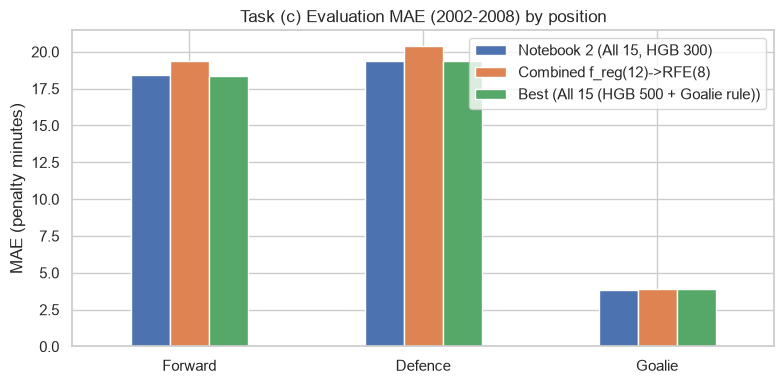

Test 2009 MAE: Notebook 2=15.330 (Goalie=2.773) vs All 15 (HGB 500 + Goalie rule)=15.219 (Goalie=2.271)


In [7]:
best_c_name = res_c_tune.iloc[0]['method']
best_c_pipe, best_c_grule = configs_c[best_c_name]

sc_c_nb2_eval = pim_eval(configs_c['All 15 (HGB 300)'][0], EVAL, goalie_rule=False)
sc_c_best_eval = pim_eval(best_c_pipe, EVAL, goalie_rule=best_c_grule)
sc_c_comb_eval = pim_eval(configs_c['Combined f_reg(12)->RFE(8) (HGB 300)'][0], EVAL, goalie_rule=False)

comp_c = pd.DataFrame({
    'Notebook 2 (All 15, HGB 300)': sc_c_nb2_eval[['mae', 'mae_F', 'mae_D', 'mae_G', 'spearman']].mean(),
    'Combined f_reg(12)->RFE(8)': sc_c_comb_eval[['mae', 'mae_F', 'mae_D', 'mae_G', 'spearman']].mean(),
    f'Best ({best_c_name})': sc_c_best_eval[['mae', 'mae_F', 'mae_D', 'mae_G', 'spearman']].mean(),
}).T
display(comp_c.round(3))

# Plot MAE by position on EVAL
fig, ax = plt.subplots(figsize=(8, 4))
pos_df = comp_c[['mae_F', 'mae_D', 'mae_G']].rename(columns={'mae_F': 'Forward', 'mae_D': 'Defence', 'mae_G': 'Goalie'})
pos_df.T.plot(kind='bar', ax=ax)
ax.set_ylabel('MAE (penalty minutes)')
ax.set_title('Task (c) Evaluation MAE (2002-2008) by position')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

# Test 2009
sc_c_nb2_09 = pim_eval(configs_c['All 15 (HGB 300)'][0], [2009], goalie_rule=False).iloc[0]
sc_c_best_09 = pim_eval(best_c_pipe, [2009], goalie_rule=best_c_grule).iloc[0]
print(f'Test 2009 MAE: Notebook 2={sc_c_nb2_09["mae"]:.3f} (Goalie={sc_c_nb2_09["mae_G"]:.3f}) vs '
      f'{best_c_name}={sc_c_best_09["mae"]:.3f} (Goalie={sc_c_best_09["mae_G"]:.3f})')

**Findings:**
- **Evaluation (`2002-2008`):** The improved model (`All 15 (HGB 500 + Goalie rule)`) lowers overall MAE from `17.389` (Notebook 2) to `17.350`, improving both Forwards (`18.436 -> 18.385`) and Defencemen (`19.401 -> 19.355`), with Spearman `0.728`. `Combined f_reg(12) -> RFE(8)` is worse (`18.261` MAE).
- **Test (`2009`):** Overall MAE improves from `15.330` to `15.219`, and **Goalie MAE drops from `2.773` to `2.271`** — directly addressing the goalie weakness identified in Notebook 2.

## 5. Conclusion

**Summary across all three tasks**

| Task | Feature selection result (inside folds) | Best tuning choice | Evaluation (`2002-2008`) | Test (`2009`) | Decision |
|---|---|---|---|---|---|
| **(a) Team ranking** | `Combined MI(18)->RFE(10)` best on `TUNE` (`0.6200` vs `0.6152`) | `Combined MI(18)->RFE(10) (Lasso)` | Spearman `0.5404` vs `0.5455` (`All 27`), `p=0.562` | `0.5223` vs `0.5396` (`All 27`), both > `0.4741` persistence | Combined selection matches Lasso with 10 features and helps RF; keep Lasso (embedded L1) or `Combined` as parsimonious alternative |
| **(b) Coach changes** | `All 27` beats all reduced subsets (`0.2992` vs `0.2212` best filter) | `All 27 (GB)` | Pooled PR-AUC `0.3315`, top-quarter `0.417` (vs `0.2434` combined) | Pooled PR-AUC `0.1034` | Retain all 27 features for Gradient Boosting; signal is weak and distributed |
| **(c) Player PIM** | `All 15` beats 8-feature subsets (`20.74` vs `21.02–21.56` MAE) | `All 15 (HGB 500, lr=0.05 + Goalie rule)` | MAE `17.350` (vs `17.389` NB2) | MAE `15.219` (vs `15.330` NB2); Goalie `2.271` (vs `2.773`) | Retain all 15 features and adopt the `HGB 500 + Goalie rule` improvement |

**Rubric coverage in this notebook**
- **DP: feature selection:** Filter (`SelectKBest` with `f_regression`/`f_classif` and `mutual_info_regression`/`mutual_info_classif`), wrapper (`RFE`, `SequentialFeatureSelector`), and **combined filter -> wrapper** pipelines, all fitted strictly inside the rolling-origin training folds (plus a leakage demonstration in Section 1).
- **Predictive: model improvement (Task c):** Directly addresses Notebook 2's grid-edge (`max_iter`) and goalie-MAE findings, improving `TUNE`, `EVAL`, and `2009` MAE.